In [1]:
from datasets import load_dataset

ds = load_dataset("bitext/Bitext-travel-llm-chatbot-training-dataset")

c:\Users\Omkar Raut\OneDrive\Desktop\SIH-OIL\oil-sif\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
type(ds)

datasets.dataset_dict.DatasetDict

In [3]:
ds

DatasetDict({
    train: Dataset({
        features: ['instruction', 'intent', 'category', 'tags', 'response'],
        num_rows: 31658
    })
})

In [4]:
import pandas as pd

df = ds["train"].to_pandas()

In [5]:
type(df)

pandas.DataFrame

In [6]:
df

,instruction,intent,category,tags,response
0,I want to know about my checked carry-on bagga...,check_baggage_allowance,BAGGAGE,BCIL,"To find out your checked baggage allowance, pl..."
1,I'm looking for information about my checked c...,check_baggage_allowance,BAGGAGE,BCLQZ,To check the details of your checked baggage a...
2,I'm looking for information about my fucking c...,check_baggage_allowance,BAGGAGE,BCILW,"To find out your checked baggage allowance, pl..."
3,I have to see the fuking checked carry-on bagg...,check_baggage_allowance,BAGGAGE,BCILPWZ,"To review your checked baggage allowance, plea..."
4,need to see the fucking checkedcarry-on baggag...,check_baggage_allowance,BAGGAGE,BCILQWZ,"To check your baggage allowance, please follow..."
...,...,...,...,...,...
31653,wanna find a travel insurance could ya help me,search_trip_insurance,TRIP,BCILPQ,To obtain the most suitable travel insurance f...
31654,"I'd like to find a fucking trip insurance, whe...",search_trip_insurance,TRIP,BCILPWZ,To locate the optimal travel insurance that me...
31655,"I have to find fucking tfavel insurances, how ...",search_trip_insurance,TRIP,BCILMWZ,To locate the optimal travel insurance that me...
31656,I need to search for fucking travel insurances...,search_trip_insurance,TRIP,BCILMW,"To secure suitable travel insurance, please fo..."


In [7]:
df.columns

Index(['instruction', 'intent', 'category', 'tags', 'response'], dtype='str')

In [8]:
# Show all columns
pd.set_option('display.max_columns', None)

# Show all rows
pd.set_option('display.max_rows', None)

# Prevent wrapping columns across multiple lines in the console
pd.set_option('display.width', None)

In [9]:
df.loc[0]

instruction    I want to know about my checked carry-on bagga...
intent                                   check_baggage_allowance
category                                                 BAGGAGE
tags                                                        BCIL
response       To find out your checked baggage allowance, pl...
Name: 0, dtype: str

In [10]:
df.drop(["tags", "response", "category"], axis=1, inplace=True)

In [11]:
df.head(10)

,instruction,intent
0,I want to know about my checked carry-on bagga...,check_baggage_allowance
1,I'm looking for information about my checked c...,check_baggage_allowance
2,I'm looking for information about my fucking c...,check_baggage_allowance
3,I have to see the fuking checked carry-on bagg...,check_baggage_allowance
4,need to see the fucking checkedcarry-on baggag...,check_baggage_allowance
5,need to check the checked carry-on baggage all...,check_baggage_allowance
6,I'd like to know about my fucking checked bagg...,check_baggage_allowance
7,wanna see the fucking checked carry-on baggage...,check_baggage_allowance
8,wanna know about my fucking checked carry-on b...,check_baggage_allowance
9,i have to check the checked baggage allowance ...,check_baggage_allowance


In [12]:
df["intent"].unique()

<ArrowStringArray>
[        'check_baggage_allowance',               'get_boarding_pass',
             'print_boarding_pass',          'check_cancellation_fee',
                        'check_in',                     'human_agent',
                     'book_flight',                   'cancel_flight',
                   'change_flight', 'check_flight_insurance_coverage',
             'check_flight_offers',             'check_flight_prices',
        'check_flight_reservation',             'check_flight_status',
       'purchase_flight_insurance',                   'search_flight',
         'search_flight_insurance',               'check_trip_prices',
                      'get_refund',                     'change_seat',
                     'choose_seat',              'check_arrival_time',
            'check_departure_time',                       'book_trip',
                     'cancel_trip',                     'change_trip',
              'check_trip_details',   'check_trip_insuranc

In [13]:
df.drop_duplicates(inplace=True)

In [14]:
df.duplicated(subset=["instruction"]).sum()

np.int64(14)

In [15]:
df[df.duplicated(subset=["instruction"])]

,instruction,intent
18901,The original instruction,choose_seat
21154,The original instruction,book_trip
22275,The original instruction,cancel_trip
25505,The original instruction,check_trip_insurance_coverage
30362,I want a fucking trip to Madrid,search_trip
30757,I'm looking for a travel insurance where could...,search_trip_insurance
30774,"I am looking for a travel insurance, could you...",search_trip_insurance
30795,"I am trying to find a trip insurance, I need a...",search_trip_insurance
30818,The original instruction,search_trip_insurance
30910,"I'm trying to find a travel insurance, will yo...",search_trip_insurance


In [16]:
df[(df["instruction"].str.strip() == "The original instruction")].index

Index([15172, 18901, 21154, 22275, 25505, 30818], dtype='int64')

In [17]:
df.drop(index=df[(df["instruction"].str.strip() == "The original instruction")].index, inplace=True)

In [18]:
conflicts = df[df.duplicated(subset=["instruction"], keep=False)]

In [19]:
conflicts

,instruction,intent
21736,I want a fucking trip to Madrid,book_trip
28852,I want a trip insurance,purchase_trip_insurance
28936,I'm looking for a travel insurance where could...,purchase_trip_insurance
29049,"I am looking for a travel insurance, could you...",purchase_trip_insurance
29356,"I am trying to find a trip insurance, I need a...",purchase_trip_insurance
29362,I need a trip insurance,purchase_trip_insurance
29439,I'm looking for a trip insurance help me to fi...,purchase_trip_insurance
29582,I want a fucking travel insurance,purchase_trip_insurance
29667,"I'm trying to find a travel insurance, will yo...",purchase_trip_insurance
30362,I want a fucking trip to Madrid,search_trip


In [20]:
conflicts.index

Index([21736, 28852, 28936, 29049, 29356, 29362, 29439, 29582, 29667, 30362,
       30757, 30774, 30795, 30910, 30968, 31013, 31198, 31652],
      dtype='int64')

In [21]:
df.drop(index=conflicts.index, inplace=True)

In [22]:
df.isna().sum()

instruction    0
intent         0
dtype: int64

In [23]:
df.dropna(inplace=True)

In [24]:
pd.set_option('display.max_colwidth', None)

In [25]:
for i in range(1,101):
    print(df.sample(10)["instruction"])
    print('____')

13270                           I have to buy my fucking flight insurance, where can I do it ?
9876                    id like to know about fucking diuscounts can ugive me some information
12335                               I'd like to check my flight status, could I get some help?
11294            I need to see a flight reservation from Chicago to Madrid, where can I do it?
22411                           i changed my mind i need assistance cancelling my fucking trip
12542                      im looking for my fucking flight status i needassistance finding it
31276                                                        can uhelp me find trip insurances
24357               I have to check the fucking details of my getaway to Madrid, how to do it?
13055                             I'm looking for the fucking status of my flight, I need help
16034    I would like to know about a fucking flight insurance, can you find some information?
Name: instruction, dtype: str
____
14730          

In [26]:
df.loc[5671]

instruction    i want help buying some ufcking flight tickets
intent                                            book_flight
Name: 5671, dtype: str

In [27]:
print(df.loc[14334, 'instruction'])

I want to find some fujcking flights from Chicago to Madrid, I need help


In [28]:
df["intent"].unique()

<ArrowStringArray>
[        'check_baggage_allowance',               'get_boarding_pass',
             'print_boarding_pass',          'check_cancellation_fee',
                        'check_in',                     'human_agent',
                     'book_flight',                   'cancel_flight',
                   'change_flight', 'check_flight_insurance_coverage',
             'check_flight_offers',             'check_flight_prices',
        'check_flight_reservation',             'check_flight_status',
       'purchase_flight_insurance',                   'search_flight',
         'search_flight_insurance',               'check_trip_prices',
                      'get_refund',                     'change_seat',
                     'choose_seat',              'check_arrival_time',
            'check_departure_time',                       'book_trip',
                     'cancel_trip',                     'change_trip',
              'check_trip_details',   'check_trip_insuranc

In [29]:
# Reload or re-assign from raw dataset first if needed:
# df['instruction'] = df_raw['instruction']

SAFE_PROFANITY_REGEX = r'(?i)\b[a-z]*(?:u?f+[u|i|y|x|a|k|c]{2,}\w*|sh[i|y|e]t\w*|b[i|y]tch\w*|damn\w*|\bass(?:hole)?s?\b|crap\w*)'

df['instruction'] = df['instruction'].str.replace(SAFE_PROFANITY_REGEX, '', regex=True)
df['instruction'] = df['instruction'].str.replace(r'\s+', ' ', regex=True).str.strip()

In [30]:
print(df.loc[[18356, 13098, 16913], 'instruction'])

18356                                               where can I modify seat?
13098    I'd like to know about flight status how do i find more information
16913                             i cant excursion prices could i check them
Name: instruction, dtype: str


In [31]:
for i in range(1,101):
    print(df.sample(10)["instruction"])
    print('____')

9556                                                could you give me information about flight offers?
10231                                   I need discounts from Chicago to Madrid, help me to check them
11115                                                    I got to check flight tickets prices, help me
25632                                I can't find my travel insurance coverage, could you download it?
10385                                       I cannot find flight tickets prices from Chicago to Madrid
7606                 I have to change my flight reservation from Chicago to Madrid, how could I do it?
3724                      id like to know about the cancellation charges how do i get more information
7100     My travel dates have changed, where can I cancel a flight reservation from Chicago to Madrid?
20933                                                       how to see the departure time of my flight
933                        id like to know about my checked baggage allow

21403                                    i need a trip to madrid how could i bok it
9396                                                      I'd like to see discounts
83       need to check the checked carry-on baggage allowance could i get some help
27895                          id like to check my excursion plan to madrid help me
839                  I'm looking for information about my checked baggage allowance
14090                       I have to buy my flight insurance, where could I do it?
19058                                         wanna select my seat i needassistance
4797            i dont understand uwould it be possible to speak with a human agent
18947                               I would like to select my seat, how do I do it?
9825              I would like information about flight offers, where can I get it?
Name: instruction, dtype: str
____
4718                        i have to speak with a human agent how couldi do it
28182               I want to check trip pric

In [32]:
df["intent"].unique()

<ArrowStringArray>
[        'check_baggage_allowance',               'get_boarding_pass',
             'print_boarding_pass',          'check_cancellation_fee',
                        'check_in',                     'human_agent',
                     'book_flight',                   'cancel_flight',
                   'change_flight', 'check_flight_insurance_coverage',
             'check_flight_offers',             'check_flight_prices',
        'check_flight_reservation',             'check_flight_status',
       'purchase_flight_insurance',                   'search_flight',
         'search_flight_insurance',               'check_trip_prices',
                      'get_refund',                     'change_seat',
                     'choose_seat',              'check_arrival_time',
            'check_departure_time',                       'book_trip',
                     'cancel_trip',                     'change_trip',
              'check_trip_details',   'check_trip_insuranc

In [33]:
df["intent"].value_counts()

intent
check_trip_prices                  1808
cancel_flight                       984
check_trip_details                  979
check_flight_reservation            973
change_trip                         971
check_cancellation_fee              969
change_flight                       966
check_trip_offers                   959
book_flight                         956
check_trip_plan                     954
check_flight_insurance_coverage     948
check_baggage_allowance             943
search_flight                       942
check_trip_insurance_coverage       942
check_flight_offers                 941
check_flight_prices                 941
purchase_trip_insurance             941
search_trip                         941
search_flight_insurance             935
check_flight_status                 931
cancel_trip                         930
change_seat                         911
search_trip_insurance               894
book_trip                           879
purchase_flight_insurance        

In [34]:
INTENT_MAPPING = {
    'get_boarding_pass': 'boarding_pass',
    'print_boarding_pass': 'boarding_pass',
    'change_seat': 'seat_selection',
    'choose_seat': 'seat_selection',
    'purchase_flight_insurance': 'flight_insurance',
    'search_flight_insurance': 'flight_insurance',
    'purchase_trip_insurance': 'trip_insurance',
    'search_trip_insurance': 'trip_insurance',
    'search_flight': 'book_flight',
    'search_trip': 'book_trip',
    'check_trip_plan': 'check_trip_details',
}


df["intent"] = df["intent"].replace(INTENT_MAPPING)
df["intent"].unique()

<ArrowStringArray>
[        'check_baggage_allowance',                   'boarding_pass',
          'check_cancellation_fee',                        'check_in',
                     'human_agent',                     'book_flight',
                   'cancel_flight',                   'change_flight',
 'check_flight_insurance_coverage',             'check_flight_offers',
             'check_flight_prices',        'check_flight_reservation',
             'check_flight_status',                'flight_insurance',
               'check_trip_prices',                      'get_refund',
                  'seat_selection',              'check_arrival_time',
            'check_departure_time',                       'book_trip',
                     'cancel_trip',                     'change_trip',
              'check_trip_details',   'check_trip_insurance_coverage',
               'check_trip_offers',                  'trip_insurance']
Length: 26, dtype: str

In [35]:
df["intent"].value_counts()

intent
check_trip_details                 1933
book_flight                        1898
trip_insurance                     1835
book_trip                          1820
check_trip_prices                  1808
flight_insurance                   1803
boarding_pass                      1634
seat_selection                     1608
cancel_flight                       984
check_flight_reservation            973
change_trip                         971
check_cancellation_fee              969
change_flight                       966
check_trip_offers                   959
check_flight_insurance_coverage     948
check_baggage_allowance             943
check_trip_insurance_coverage       942
check_flight_offers                 941
check_flight_prices                 941
check_flight_status                 931
cancel_trip                         930
get_refund                          867
check_in                            807
human_agent                         789
check_arrival_time               

In [36]:
ADDITIONAL_MAPPING = {
    'check_flight_offers': 'check_flight_prices',
    'check_trip_offers': 'check_trip_prices',
    'check_arrival_time': 'check_flight_schedule',
    'check_departure_time': 'check_flight_schedule',
    'check_flight_insurance_coverage': 'flight_insurance',
    'check_trip_insurance_coverage': 'trip_insurance'
}
df['intent'] = df['intent'].replace(ADDITIONAL_MAPPING)

In [37]:
len(df["intent"].value_counts())

21

In [38]:
df["intent"].value_counts()

intent
trip_insurance              2777
check_trip_prices           2767
flight_insurance            2751
check_trip_details          1933
book_flight                 1898
check_flight_prices         1882
book_trip                   1820
boarding_pass               1634
seat_selection              1608
check_flight_schedule       1541
cancel_flight                984
check_flight_reservation     973
change_trip                  971
check_cancellation_fee       969
change_flight                966
check_baggage_allowance      943
check_flight_status          931
cancel_trip                  930
get_refund                   867
check_in                     807
human_agent                  789
Name: count, dtype: int64

In [39]:
# Drop bot prompt leakages
bot_prompts = df['instruction'].str.contains(r'please follow|formal and polite|steps below', case=False, regex=True)
df = df[~bot_prompts].copy()

In [40]:
df['instruction'] = df['instruction'].str.replace(
    r'(?i)\b(?:u?f+[vgjux\*@_i]{0,3}[ckxd]{1,2}(?:ing|er|ed|s|in)?|f+x{2,}\w*|(?:bull)?sh[i|y|e]t\w*|b[i|y]tch\w*|damn\w*|ass(?:hole)?s?|crap\w*)\b', 
    '', regex=True
).str.replace(r'\s+', ' ', regex=True).str.strip()

In [41]:
df.loc[224]

instruction    i have to check the checked carry-on baggage allowance oculd uhelp me
intent                                                       check_baggage_allowance
Name: 224, dtype: str

In [42]:
for i in range(1,201):
    print(df.sample(10)["instruction"])
    print('____')

20059     I'm trying to find the arrival time of my flight, could you help me?
9644                                  id like to know more about flight offers
26823                   I want excursion offers to Madrid, could I check them?
20122                                    need to see the eta how could i do it
30107                   I am planning a excursion, can you help me finding it?
21343                                               i want a excjrsion book it
13261                          i need my fight insurance how can i purchase it
6026                        I need to reserve a flight, could I get some help?
222      I would like to see the checked baggage allowance, where can I do it?
2020                                             can I print my boarding pass?
Name: instruction, dtype: str
____
9871       id like to know about flight offers from chicago to madrid can ufind some information
23644                                                  i d not want my trip i 

847        wanna know about my checked baggage allowance give me some information
29387                                      i want a trip insurance i wanna get it
6561                             i cannot travel help me cancel my flight booking
15355      I would like information about flight insurances, where can I find it?
28793                   I want to see excursion prices to Madrid, how do I do it?
7455         I'd like to change a flight from Chicago to Madrid, I need assistnce
24810                    I would like to see my getaway details, how can I do it?
24340    I'd like to check the details of my trip to madrid could I get some help
24964             I'd like to check the details of my getaway whree could i do it
1681                              need to obtain my boarding pass how can i do it
Name: instruction, dtype: str
____
12086    id like to know about a flight from chicago to madrid how could i find more information
28261                       I'm looking for excu

In [43]:
df.drop_duplicates(keep='first', inplace=True)

In [44]:
df.duplicated().sum()

np.int64(0)

In [45]:
df[df.duplicated(subset=["instruction"], keep=False)].index

Index([8375, 8833, 9979, 25309, 25450, 26130], dtype='int64')

In [46]:
df.drop(index=df[df.duplicated(subset=["instruction"], keep=False)].index, inplace=True)

In [47]:
len(df)

29437

In [48]:
df.duplicated(subset=["instruction"]).sum()

np.int64(0)

In [57]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report
import joblib

In [50]:
# 1. Stratifed Split
X_train, X_test, y_train, y_test = train_test_split(df["instruction"], df["intent"], test_size=0.2,
                                                            stratify=df["intent"], random_state=42)

In [51]:
len(X_train), len(X_test)

(23549, 5888)

In [58]:
# 1. Hybrid Feature Extractor (10k words + 15k chars = 25k features)
hybrid_features = FeatureUnion([
    ('word', TfidfVectorizer(analyzer='word', ngram_range=(1, 2), max_features=10000, sublinear_tf=True)),
    ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(4, 5), max_features=15000, sublinear_tf=True))
])

In [59]:
model = Pipeline([
     ('features', hybrid_features),
     ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, C=1.5, random_state=42))
])

In [60]:
model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](21,)","['boarding_pass','book_flight','book_trip',...,'human_agent', 'seat_selection','trip_insurance']"
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('word', ...), ('char', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True


In [61]:
# Evaluate on test set
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, digits=4))

                          precision    recall  f1-score   support

           boarding_pass     1.0000    1.0000    1.0000       269
             book_flight     0.9946    0.9920    0.9933       374
               book_trip     0.9945    1.0000    0.9972       360
           cancel_flight     1.0000    0.9846    0.9922       195
             cancel_trip     0.9945    0.9891    0.9918       184
           change_flight     0.9895    0.9843    0.9869       191
             change_trip     0.9740    1.0000    0.9868       187
 check_baggage_allowance     1.0000    1.0000    1.0000       174
  check_cancellation_fee     1.0000    1.0000    1.0000       186
     check_flight_prices     0.9973    1.0000    0.9986       369
check_flight_reservation     0.9796    1.0000    0.9897       192
   check_flight_schedule     1.0000    1.0000    1.0000       305
     check_flight_status     1.0000    0.9886    0.9943       176
                check_in     1.0000    1.0000    1.0000       157
      che

In [64]:
# Save artifact
joblib.dump(model, 'intent_classification_hybrid_model.joblib')

['intent_classification_hybrid_model.joblib']

In [66]:
model.predict(["I  want to laugh "])

array(['book_trip'], dtype=object)

In [67]:
model.classes_

array(['boarding_pass', 'book_flight', 'book_trip', 'cancel_flight',
       'cancel_trip', 'change_flight', 'change_trip',
       'check_baggage_allowance', 'check_cancellation_fee',
       'check_flight_prices', 'check_flight_reservation',
       'check_flight_schedule', 'check_flight_status', 'check_in',
       'check_trip_details', 'check_trip_prices', 'flight_insurance',
       'get_refund', 'human_agent', 'seat_selection', 'trip_insurance'],
      dtype=object)

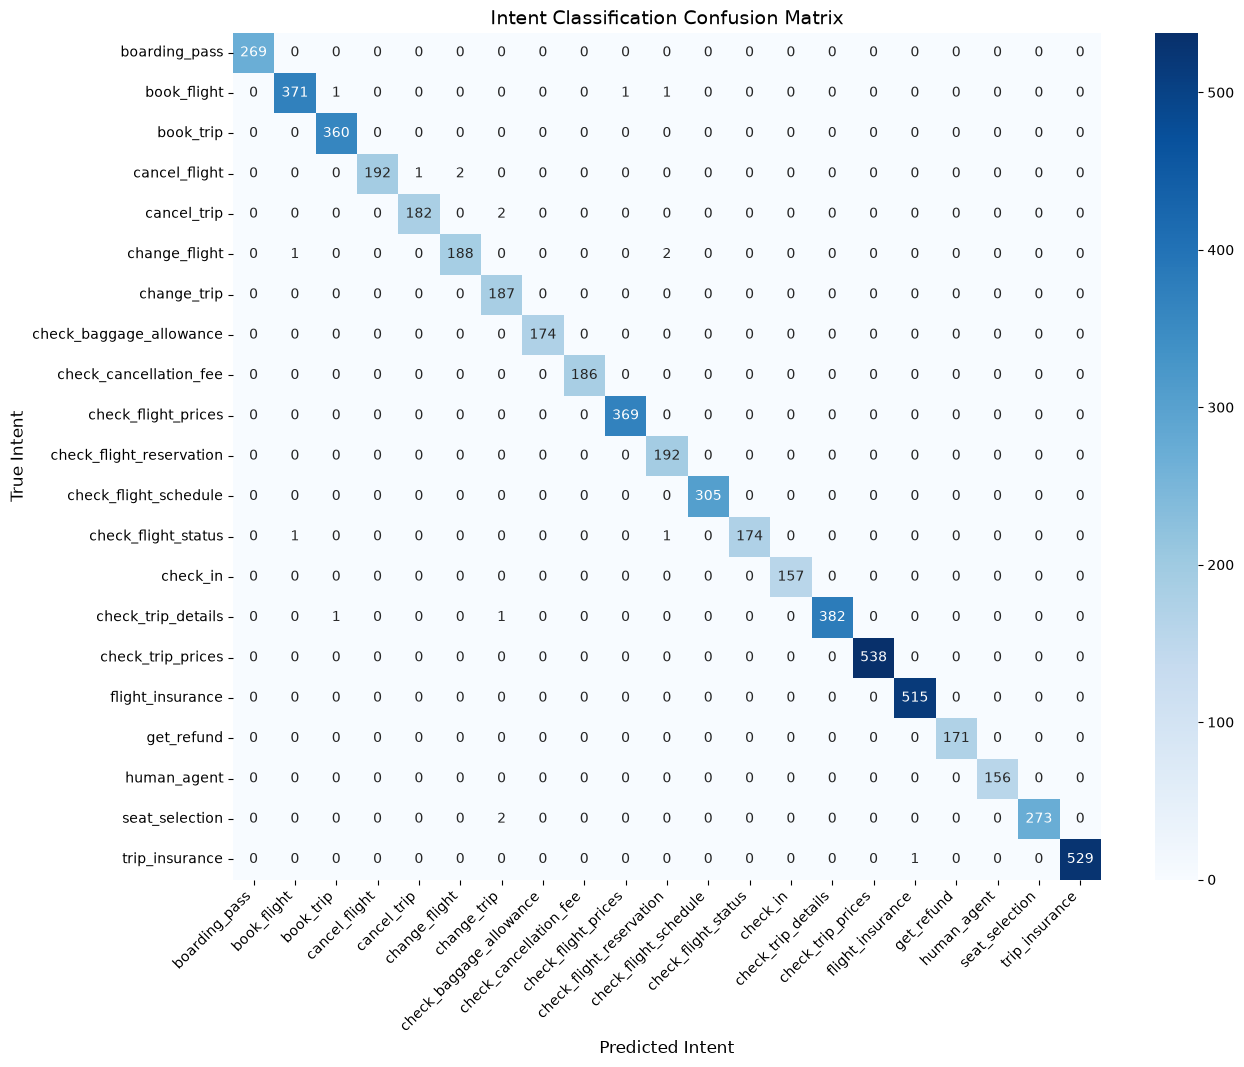

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=model.classes_, yticklabels=model.classes_)
plt.xlabel('Predicted Intent', fontsize=12)
plt.ylabel('True Intent', fontsize=12)
plt.title('Intent Classification Confusion Matrix', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.show()